# Part 2 — grouped five-fold sigmoid calibration

Reproduce the fixed pooled criteria/phase C=1 winner and training-only five-fold OOF calibration. Compare the uncalibrated baseline, a pooled sigmoid, and phase-specific sigmoids. Historical validation losses are 0.57375, 0.57221 and 0.57261 respectively. Positive sigmoid slopes preserve within-phase rankings. Full mode refits the same baseline from the CSVs rather than requiring the original pickle.

This notebook embeds the source implementation; it does not import project-specific Python modules. Standard-library and third-party imports are sufficient. Run cells in order from a fresh kernel. Default verification mode reads explicitly labeled historical references without fitting. Set `RUN_FULL=True` for fresh computation. All generated outputs are isolated under `reproduced/`.


## Integrated deliverable provenance

Source: the original Part 2 implementation. Model features, hyperparameters, splits and calibration procedure are unchanged. Part 1 references in preservation hashes are administrative only. For the authoritative cross-part error analysis use part2_error_analysis.ipynb. All new output paths below use reproduced/.


## Imports, paths, execution mode and preservation checks


In [1]:
from pathlib import Path
import os
import hashlib
import json
# Configure numerical thread limits before NumPy/scikit-learn are imported.
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = next((p for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             for p in (parent / 'midterm', parent)
             if (p / 'part1-data').is_dir() and (p / 'part2-data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the repository or assembled midterm folder with both data directories.')
REPRO_ROOT = ROOT / 'reproduced'
RUN_FULL = False  # Change to True for fresh complete training; verify mode never fits models.
# Original artifacts are read-only references. Every newly generated artifact stays below REPRO_ROOT.
def protected_hashes():
    paths = []
    for directory in ('part1-data', 'part2-data', 'outputs', 'part1-results', 'part2-results',
                      'part2/outputs', 'part2/calibration_outputs', 'writeup'):
        if (ROOT / directory).exists():
            paths.extend(p for p in (ROOT / directory).rglob('*') if p.is_file())
    paths.extend(ROOT.glob('*.py'))
    paths.extend((ROOT / 'part2').glob('*.py'))
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
ORIGINAL_HASHES = protected_hashes()
print('Mode:', 'full fresh reproduction' if RUN_FULL else 'verification only — no model fitting')


Mode: verification only — no model fitting


In [2]:
DATA = ROOT / 'part2-data'
OUTPUT = REPRO_ROOT / 'part2_modeling'
REFERENCE_OUTPUT = ROOT / 'part2' / 'outputs'
REFERENCE_CALIBRATION = ROOT / 'part2' / 'calibration_outputs'
SEED = 5785
PHASES = ('I', 'II', 'III')
TEXT_SETS = {
    'clinical': ('diseases_cleaned', 'drugs', 'icdcodes'),
    'criteria': ('criteria',),
    'all_text': ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes'),
}
CS = (0.1, 1.0, 10.0)
THRESHOLD = 0.5
OUTPUT.mkdir(parents=True, exist_ok=True)


In [3]:
import ast
import re
import pandas as pd


In [4]:
TEXT_COLUMNS = ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes')


### `load_data`

Implementation copied from `part2/data.py`.


In [5]:
def load_data():
    names = ('outcome_train', 'outcome_val', 'outcome_test', 'part2_sample_submission')
    missing = [str(DATA / f'{n}.csv') for n in names if not (DATA / f'{n}.csv').exists()]
    if missing:
        raise FileNotFoundError(f'Missing files: {missing}')
    train, val, test, sample = [pd.read_csv(DATA / f'{n}.csv') for n in names]
    for frame, expected in zip((train, val, test), (8037, 1013, 1500)):
        assert len(frame) == expected
        assert frame.ID.is_unique and frame.ID.notna().all()
        assert frame.trial_id.notna().all()
        assert set(frame.phase) == set(PHASES)
        assert not frame.duplicated(['trial_id', 'phase']).any()
        assert frame.ID.eq(frame.trial_id + '_' + frame.phase).all()
        assert set(TEXT_COLUMNS + ('start_year',)).issubset(frame.columns)
    for frame in (train, val):
        assert set(frame.label) == {0, 1}
        assert frame.groupby('trial_id').label.nunique().max() == 1
    for a, b in ((train, val), (train, test), (val, test)):
        assert not set(a.trial_id).intersection(b.trial_id), 'Cross-split trial leakage'
    assert sample.ID.equals(test.ID)
    assert list(sample.columns) == ['ID', 'label']
    return train, val, test, sample


### `flatten`

Implementation copied from `part2/data.py`.


In [6]:
def flatten(value):
    """Decode nested Python-list strings safely (including nested ICD lists)."""
    if isinstance(value, (list, tuple)):
        return ' '.join(flatten(v) for v in value)
    if pd.isna(value):
        return ''
    value = str(value).strip()
    if value.startswith('['):
        try:
            return flatten(ast.literal_eval(value))
        except (ValueError, SyntaxError):
            pass
    return re.sub(r'\s+', ' ', value).strip()


### `prepare`

Implementation copied from `part2/data.py`.


In [7]:
def prepare(frame):
    # Explicit allowlist: IDs, labels, reason labels/embeddings never enter features.
    result = frame[list(TEXT_COLUMNS) + ['phase', 'start_year']].copy()
    for col in TEXT_COLUMNS:
        result[col] = result[col].map(flatten)
    return result


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


### `build_features`

Implementation copied from `part2/features.py`.


In [9]:
def build_features(text_columns, use_year, pooled):
    transformers = []
    for col in text_columns:
        transformers.append((col, TfidfVectorizer(
            lowercase=True, strip_accents='unicode', ngram_range=(1, 2),
            min_df=3, max_df=1.0, sublinear_tf=True,
            # Preserve decimal ICD codes as tokens, including one-character words.
            token_pattern=r'(?u)\b\w[\w.]*\b',
            max_features=15000 if col == 'criteria' else 5000), col))
    if pooled:
        transformers.append(('phase', OneHotEncoder(handle_unknown='ignore'), ['phase']))
    if use_year:
        transformers.append(('year', Pipeline([
            ('impute', SimpleImputer(strategy='median', add_indicator=True)),
            ('scale', StandardScaler()),
        ]), ['start_year']))
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0)


In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression


### `fit_features`

Implementation copied from `part2/training.py`.


In [11]:
def fit_features(train, val, text_columns, use_year, regime):
    groups = ('pooled',) if regime == 'pooled' else PHASES
    prepared = {}
    for group in groups:
        tm = np.ones(len(train), dtype=bool) if group == 'pooled' else train.phase.eq(group).to_numpy()
        vm = np.ones(len(val), dtype=bool) if group == 'pooled' else val.phase.eq(group).to_numpy()
        features = build_features(text_columns, use_year, regime == 'pooled')
        xt = features.fit_transform(train.loc[tm])
        xv = features.transform(val.loc[vm])
        prepared[group] = (features, xt, xv, tm, vm)
    return prepared


### `fit_classifiers`

Implementation copied from `part2/training.py`.


In [12]:
def fit_classifiers(prepared, labels, c):
    train_p = np.empty(len(labels))
    val_p = np.empty(sum(int(v[4].sum()) for v in prepared.values()))
    models = {}
    for group, (features, xt, xv, tm, vm) in prepared.items():
        model = LogisticRegression(C=c, solver='liblinear', max_iter=2000, tol=1e-5, random_state=SEED)
        model.fit(xt, labels[tm])
        if model.n_iter_.max() >= model.max_iter:
            raise RuntimeError(f'Nonconvergence for {group}, C={c}')
        train_p[tm] = model.predict_proba(xt)[:, 1]
        val_p[vm] = model.predict_proba(xv)[:, 1]
        models[group] = dict(features=features, classifier=model)
    return models, train_p, val_p


### `predict`

Implementation copied from `part2/training.py`.


In [13]:
def predict(bundle, frame):
    if bundle['kind'] == 'prior':
        return frame.phase.map(bundle['priors']).to_numpy(dtype=float)
    p = np.empty(len(frame))
    for group, components in bundle['models'].items():
        mask = np.ones(len(frame), dtype=bool) if group == 'pooled' else frame.phase.eq(group).to_numpy()
        if mask.any():
            x = components['features'].transform(frame.loc[mask])
            p[mask] = components['classifier'].predict_proba(x)[:, 1]
    return p


In [14]:
import numpy as np
from sklearn.metrics import log_loss, f1_score, roc_auc_score, average_precision_score


### `evaluate`

Implementation copied from `part2/evaluation.py`.


In [15]:
def evaluate(frame, probabilities):
    p = np.asarray(probabilities, dtype=float)
    if p.shape != (len(frame),) or not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Expected one finite probability per row in [0, 1]')
    result = {}
    for phase in ('overall', *PHASES):
        mask = np.ones(len(frame), dtype=bool) if phase == 'overall' else frame.phase.eq(phase).to_numpy()
        y, pred = frame.label.to_numpy()[mask], p[mask]
        result[f'{phase}_n'] = len(y)
        if not len(y):
            for metric in ('log_loss', 'f1', 'roc_auc', 'average_precision'):
                result[f'{phase}_{metric}'] = np.nan
            continue
        result[f'{phase}_log_loss'] = log_loss(y, pred, labels=[0, 1])
        result[f'{phase}_f1'] = f1_score(y, pred >= THRESHOLD, zero_division=0)
        both = len(np.unique(y)) == 2
        result[f'{phase}_roc_auc'] = roc_auc_score(y, pred) if both else np.nan
        result[f'{phase}_average_precision'] = average_precision_score(y, pred) if both else np.nan
    result['phase_macro_log_loss'] = np.mean([result[f'{p}_log_loss'] for p in PHASES])
    return result


In [16]:
import pickle
import numpy as np
import pandas as pd


### `validate_submission`

Implementation copied from `part2/submission.py`.


In [17]:
def validate_submission(submission, test, sample):
    assert list(submission.columns) == ['ID', 'label']
    assert len(submission) == len(test) == 1500
    assert submission.ID.equals(test.ID) and submission.ID.equals(sample.ID)
    assert submission.ID.is_unique and not submission.isna().any().any()
    assert np.isfinite(submission.label).all() and submission.label.between(0, 1).all()


### `generate`

Implementation copied from `part2/submission.py`.


In [18]:
def generate(bundle, test, sample):
    submission = pd.DataFrame({'ID': test.ID, 'label': predict(bundle, prepare(test))})
    validate_submission(submission, test, sample)
    path = OUTPUT / 'part2_submission.csv'
    submission.to_csv(path, index=False)
    validate_submission(pd.read_csv(path), test, sample)
    return path


In [19]:
import json
import pandas as pd


### `markdown_table`

Implementation copied from `part2/report.py`.


In [20]:
def markdown_table(frame):
    def fmt(v):
        return f'{v:.5f}' if isinstance(v, float) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, frame.columns)) + ' |',
                      '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |',
                      *['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in frame.itertuples(index=False, name=None)]])


## Calibration methodology

The exact copied functions below implement phase/outcome-stratified trial-group folds, raw logistic margins, unpenalized Platt fitting and inference. In full mode the same base pipeline is freshly fitted once; the five OOF pipelines fit TF-IDF on their own training folds. Calibrators see only training OOF margins/labels. At inference they transform the full-training base model. The 80%-versus-100% training-size mismatch is unchanged. No validation labels fit the sigmoid.


In [21]:
import hashlib
import json
import pickle
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import StratifiedGroupKFold


In [22]:
CAL_OUTPUT = REPRO_ROOT / 'part2_calibration'
N_FOLDS = 5


### `diagnostics`

Implementation copied from `part2/calibration.py`.


In [23]:
def diagnostics(frame, probabilities, candidate, split='validation'):
    """Fixed-width bins [left,right), including probability 1 in the final bin."""
    p = np.asarray(probabilities, dtype=float)
    metrics = evaluate(frame, p)
    summary, bins = [], []
    for phase in ('overall', *PHASES):
        mask = np.ones(len(frame), dtype=bool) if phase == 'overall' else frame.phase.eq(phase).to_numpy()
        y, q = frame.label.to_numpy()[mask], p[mask]
        bucket = np.minimum((q * 10).astype(int), 9)
        gaps, weights = [], []
        for b in range(10):
            selected = bucket == b
            n = int(selected.sum())
            mean = float(q[selected].mean()) if n else np.nan
            observed = float(y[selected].mean()) if n else np.nan
            bins.append(dict(candidate=candidate, split=split, phase=phase, bin=b,
                lower=b / 10, upper=(b + 1) / 10, n=n,
                successes=int(y[selected].sum()), mean_probability=mean,
                observed_success_rate=observed, gap=mean - observed))
            if n:
                gaps.append(abs(mean - observed))
                weights.append(n)
        row = dict(candidate=candidate, split=split, phase=phase, n=len(y),
            log_loss=metrics[f'{phase}_log_loss'], brier_score=brier_score_loss(y, q),
            mean_probability=float(q.mean()), observed_success_rate=float(y.mean()),
            mean_gap=float(q.mean() - y.mean()),
            ece_10_bins=float(np.average(gaps, weights=weights)),
            f1=metrics[f'{phase}_f1'], roc_auc=metrics[f'{phase}_roc_auc'],
            average_precision=metrics[f'{phase}_average_precision'])
        # Both confident-success and confident-failure tails; gaps alone aren't sharpness.
        for name, tail in [('high', q >= .8), ('low', q < .2)]:
            row[f'{name}_n'] = int(tail.sum())
            row[f'{name}_mean_probability'] = float(q[tail].mean()) if tail.any() else np.nan
            row[f'{name}_success_rate'] = float(y[tail].mean()) if tail.any() else np.nan
        summary.append(row)
    return pd.DataFrame(summary), pd.DataFrame(bins)


### `grouped_folds`

Implementation copied from `part2/calibration.py`.


In [24]:
def grouped_folds(train, n_splits=N_FOLDS):
    # Stratification approximates joint phase/outcome balance without splitting trials.
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    strata = train.phase.astype(str) + '_' + train.label.astype(str)
    folds = list(splitter.split(train, strata, groups=train.trial_id))
    seen = np.zeros(len(train), dtype=int)
    for fit, held in folds:
        assert not set(train.iloc[fit].trial_id) & set(train.iloc[held].trial_id)
        assert set(train.iloc[fit].phase) == set(PHASES)
        seen[held] += 1
    assert (seen == 1).all()
    return folds


### `decision_scores`

Implementation copied from `part2/calibration.py`.


In [25]:
def decision_scores(baseline, features):
    components = baseline['models']['pooled']
    return components['classifier'].decision_function(components['features'].transform(features))


### `fit_sigmoids`

Implementation copied from `part2/calibration.py`.


In [26]:
def fit_sigmoids(scores, labels, phases, phase_specific=False):
    calibrators = {}
    for group in PHASES if phase_specific else ('pooled',):
        mask = np.ones(len(labels), dtype=bool) if group == 'pooled' else np.asarray(phases) == group
        assert len(np.unique(labels[mask])) == 2
        # Fixed, unpenalized two-parameter Platt sigmoid on raw decision margins.
        calibrator = LogisticRegression(C=np.inf, solver='lbfgs', tol=1e-10,
                                        max_iter=2000, random_state=SEED)
        calibrator.fit(np.asarray(scores)[mask, None], labels[mask])
        assert calibrator.n_iter_.max() < calibrator.max_iter
        assert calibrator.coef_[0, 0] > 0, 'Unexpected ranking reversal'
        calibrators[group] = calibrator
    return calibrators


### `apply_sigmoids`

Implementation copied from `part2/calibration.py`.


In [27]:
def apply_sigmoids(calibrators, scores, phases):
    p = np.empty(len(scores))
    for group, model in calibrators.items():
        mask = np.ones(len(scores), dtype=bool) if group == 'pooled' else np.asarray(phases) == group
        if mask.any():
            p[mask] = model.predict_proba(np.asarray(scores)[mask, None])[:, 1]
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p


### `calibrated_predict`

Implementation copied from `part2/calibration.py`.


In [28]:
def calibrated_predict(bundle, frame):
    features = prepare(frame)
    return apply_sigmoids(bundle['calibrators'], decision_scores(bundle['baseline'], features), frame.phase)


### `main`

Implementation copied from `part2/calibration.py`.


In [29]:
def run_calibration_experiment():
    protected = fingerprints()
    CAL_OUTPUT.mkdir(parents=True, exist_ok=True)
    train, val, test, sample = load_data()
    saved_path = REFERENCE_OUTPUT / 'best_validation_predictions.csv'
    saved = pd.read_csv(saved_path) if saved_path.exists() else None
    if saved is not None:
        assert saved.ID.equals(val.ID) and saved.trial_id.equals(val.trial_id)
        assert saved.phase.equals(val.phase) and saved.label.equals(val.label)
    # Notebook adaptation: recreate the identical fixed base model from datasets.
    fixed_features = fit_features(prepare(train), prepare(val), ('criteria',), False, 'pooled')
    fixed_models, _, _ = fit_classifiers(fixed_features, train.label.to_numpy(), 1.0)
    baseline = dict(kind='logistic', models=fixed_models,
                    config=dict(experiment='criteria_year0_pooled_C1'))
    xt, xv = prepare(train), prepare(val)
    baseline_p = predict(baseline, xv)
    if saved is not None:
        assert np.allclose(baseline_p, saved.probability, rtol=0, atol=1e-6)
    baseline_summary, baseline_bins = diagnostics(val, baseline_p, 'baseline')
    baseline_summary.to_csv(CAL_OUTPUT / 'baseline_calibration_summary.csv', index=False)
    baseline_bins.to_csv(CAL_OUTPUT / 'baseline_calibration_bins.csv', index=False)
    print('EXISTING MODEL DIAGNOSTICS\n' + baseline_summary.to_string(index=False), flush=True)
    print('PHASE III BINS\n' + baseline_bins.query("phase == 'III'").to_string(index=False), flush=True)

    scores = np.full(len(train), np.nan)
    fold_ids = np.full(len(train), -1)
    fold_balance = []
    for fold, (fit, held) in enumerate(grouped_folds(train)):
        fitted = fit_features(xt.iloc[fit], xt.iloc[held], ('criteria',), False, 'pooled')
        models, _, _ = fit_classifiers(fitted, train.label.to_numpy()[fit], 1.0)
        fold_bundle = dict(kind='logistic', models=models)
        scores[held] = decision_scores(fold_bundle, xt.iloc[held])
        fold_ids[held] = fold
        for role, indexes in [('base_fit', fit), ('calibration_oof', held)]:
            for phase, group in train.iloc[indexes].groupby('phase'):
                fold_balance.append(dict(fold=fold, role=role, phase=phase, n=len(group),
                    n_trials=group.trial_id.nunique(), successes=int(group.label.sum()),
                    success_rate=float(group.label.mean())))
        print(f'OOF fold {fold + 1}/{N_FOLDS}: fit={len(fit)}, held={len(held)}', flush=True)
    assert np.isfinite(scores).all() and (fold_ids >= 0).all()
    assert pd.DataFrame({'trial_id': train.trial_id, 'fold': fold_ids}).groupby('trial_id').fold.nunique().max() == 1
    oof = train[['ID', 'trial_id', 'phase', 'label']].copy()
    oof['fold'] = fold_ids
    oof['decision_score'] = scores
    oof.to_csv(CAL_OUTPUT / 'training_oof_scores.csv', index=False)
    pd.DataFrame(fold_balance).to_csv(CAL_OUTPUT / 'fold_balance.csv', index=False)
    # All calibrators are fitted BEFORE evaluating any calibrated validation predictions.
    candidates = {name: fit_sigmoids(scores, train.label.to_numpy(), train.phase, separate)
                  for name, separate in [('sigmoid_pooled', False), ('sigmoid_by_phase', True)]}
    parameters = [dict(candidate=name, group=group, slope=float(model.coef_[0, 0]),
                       intercept=float(model.intercept_[0]),
                       n_fit=len(train) if group == 'pooled' else int(train.phase.eq(group).sum()))
                  for name, calibrators in candidates.items() for group, model in calibrators.items()]
    pd.DataFrame(parameters).to_csv(CAL_OUTPUT / 'sigmoid_parameters.csv', index=False)
    full_scores = decision_scores(baseline, xv)
    summaries, bins = [baseline_summary], [baseline_bins]
    predictions = []
    bundles = {}
    for name in ('baseline', *candidates):
        if name == 'baseline':
            p = baseline_p
        else:
            p = apply_sigmoids(candidates[name], full_scores, val.phase)
            summary, bin_table = diagnostics(val, p, name)
            summaries.append(summary)
            bins.append(bin_table)
            bundles[name] = dict(baseline=baseline, calibrators=candidates[name],
                                 method=name, training='5-fold grouped OOF; frozen full-training base model')
        record = val[['ID', 'trial_id', 'phase', 'label']].copy()
        record['candidate'] = name
        record['probability'] = p
        record['predicted_label'] = (p >= THRESHOLD).astype(int)
        predictions.append(record)
    results = pd.concat(summaries, ignore_index=True)
    bin_table = pd.concat(bins, ignore_index=True)
    results.to_csv(CAL_OUTPUT / 'validation_metrics.csv', index=False)
    bin_table.to_csv(CAL_OUTPUT / 'validation_calibration_bins.csv', index=False)
    pd.concat(predictions, ignore_index=True).to_csv(CAL_OUTPUT / 'validation_predictions.csv', index=False)
    losses = results.loc[results.phase.eq('overall')].set_index('candidate').log_loss
    winner = losses.idxmin()
    submissions = []
    # Save each improving candidate, with its own model and distinct submission filename.
    for name, bundle in bundles.items():
        if losses[name] < min(losses['baseline'], 0.57375):
            with (CAL_OUTPUT / f'{name}_model.pkl').open('wb') as handle:
                pickle.dump(bundle, handle)
            submission = pd.DataFrame({'ID': test.ID, 'label': calibrated_predict(bundle, test)})
            path = CAL_OUTPUT / f'{name}_candidate_submission.csv'
            validate_submission(submission, test, sample)
            submission.to_csv(path, index=False)
            validate_submission(pd.read_csv(path), test, sample)
            with (CAL_OUTPUT / f'{name}_model.pkl').open('rb') as handle:
                reloaded = pickle.load(handle)
            assert np.allclose(calibrated_predict(reloaded, test), submission.label, rtol=0, atol=1e-14)
            submissions.append(path.name)
    # Independent formulas verify every summary and every bin without refitting.
    all_predictions = pd.concat(predictions, ignore_index=True)
    for row in results.itertuples(index=False):
        rows = all_predictions.loc[all_predictions.candidate.eq(row.candidate)]
        if row.phase != 'overall':
            rows = rows.loc[rows.phase.eq(row.phase)]
        y, p = rows.label.to_numpy(), rows.probability.to_numpy()
        assert np.isclose(np.mean((p-y)**2), row.brier_score)
        assert np.isclose(-np.mean(y*np.log(p)+(1-y)*np.log1p(-p)), row.log_loss)
        b = bin_table.loc[bin_table.candidate.eq(row.candidate) & bin_table.phase.eq(row.phase)]
        assert b.n.sum() == len(rows) and b.successes.sum() == rows.label.sum()
        assert np.isclose((b.mean_probability.fillna(0)*b.n).sum()/len(rows), p.mean())
    after = fingerprints()
    assert all(after.get(path) == digest for path, digest in protected.items())
    metadata = dict(seed=SEED, folds=N_FOLDS, threshold=THRESHOLD,
        method='5-fold StratifiedGroupKFold, phase x outcome strata, trial_id groups',
        calibration_fit='unpenalized logistic regression of training labels on OOF raw decision scores',
        inference='apply learned sigmoid to original full-training frozen baseline scores; no ensemble',
        validation_used_for='diagnostics, evaluation and selection only',
        baseline_log_loss=float(losses['baseline']), best_candidate=winner,
        candidate_submissions=submissions, protected_files_unchanged=True, protected_sha256=protected,
        python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__, numpy=np.__version__)
    (CAL_OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
    write_report(results, baseline_bins, pd.DataFrame(parameters), winner, submissions)
    print(markdown_table(results[['candidate','phase','log_loss','brier_score','mean_probability','observed_success_rate']]))
    print('Best:', winner, 'Submissions:', submissions)


### `comparison_interpretation`

Implementation copied from `part2/calibration.py`.


In [30]:
def comparison_interpretation(results):
    table = results.set_index(['candidate', 'phase'])
    base, pooled, phase = (table.loc[(name, 'overall')] for name in
                           ('baseline', 'sigmoid_pooled', 'sigmoid_by_phase'))
    b3, p3, s3 = (table.loc[(name, 'III')] for name in
                  ('baseline', 'sigmoid_pooled', 'sigmoid_by_phase'))
    return [f'Pooled sigmoid changes overall log loss from {base.log_loss:.6f} to {pooled.log_loss:.6f} '
            f'(delta {pooled.log_loss-base.log_loss:+.6f}) and Phase III from {b3.log_loss:.6f} '
            f'to {p3.log_loss:.6f}. Overall Brier changes from {base.brier_score:.6f} '
            f'to {pooled.brier_score:.6f}; Phase III Brier from {b3.brier_score:.6f} '
            f'to {p3.brier_score:.6f}. Phase-specific sigmoid gives overall log loss '
            f'{phase.log_loss:.6f} and Phase III {s3.log_loss:.6f}. '
            'It helps Phase III more but worsens Phase I and has worse overall loss than pooled calibration. '
            'The overall improvements are small; this experiment does not establish statistical significance '
            'or guarantee improvement on later test trials. No calibration or temporal hyperparameter search '
            'was performed.', '']


### `write_report`

Implementation copied from `part2/calibration.py`.


In [31]:
def write_report(results, baseline_bins, parameters, winner, submissions):
    lines = ['# Targeted probability-calibration experiment', '',
        'The original pooled criteria + phase logistic model (C=1, no year) is frozen. '
        'All existing artifacts are unchanged. This experiment uses no Part 1 data.', '',
        '## Existing model calibration', '',
        markdown_table(results.loc[results.candidate.eq('baseline'),
            ['phase','n','mean_probability','observed_success_rate','mean_gap','brier_score','ece_10_bins']]), '',
        'Positive mean gaps indicate average success overprediction; they do not establish overconfidence '
        'across the probability range. Overconfidence means probabilities are too extreme relative to observed '
        'frequencies. Brier score measures both calibration and discrimination. ECE is a descriptive ten-bin '
        'statistic sensitive to binning and sampling noise, not the model-selection criterion.', '',
        'Phase III does not show broad overconfidence on validation: its mean predicted success is '
        '66.05%, nearly the observed 66.12%. Among the 79 predictions >=0.8, mean probability is '
        '85.80% but observed success is 92.41%, indicating underconfidence in that tail. The '
        '0.4–0.5 bin overpredicts success (45.21% predicted versus 26.47% observed, n=34), while '
        'the 0.8–0.9 bin underpredicts it (84.94% versus 91.30%, n=69). Thus miscalibration is mixed; '
        'high false-success rates among unsuccessful trials alone do not establish overconfidence. '
        'Low-probability Phase III bins are small and noisy.', '',
        'Phase III fixed-width reliability bins (empty-bin statistics are undefined):', '',
        markdown_table(baseline_bins.loc[baseline_bins.phase.eq('III'),
            ['lower','upper','n','successes','mean_probability','observed_success_rate','gap']]), '',
        '## Procedure and fairness', '',
        'Five StratifiedGroupKFold splits use training trial_id as the group and phase × label as the '
        'stratification target. Trial IDs never cross fit/held folds; combined-phase rows stay together. '
        'Every fold refits the original TF-IDF/phase preprocessing and the same C=1 classifier using '
        'only that fold’s fit rows. Exactly one out-of-fold raw decision margin is generated per training row. '
        'No validation text or labels enter these fits.', '',
        'Two prespecified calibration candidates are fitted to all training OOF margins: one global sigmoid '
        'and independent sigmoids by phase. Each is an unpenalized two-parameter logistic regression; '
        'Phase I/II/III provide 1,012/3,950/3,075 OOF rows, each with both classes. '
        'The calibrators are fitted before computing calibrated validation predictions. F1 uses >=0.5. '
        'No threshold search or other model changes are made.', '',
        'For validation/test, both mappings transform raw margins from the exact original full-training '
        'baseline. Thus inference uses identical base predictions for all candidates. The OOF models see '
        '80% of training trials whereas the frozen base saw 100%; this common non-ensemble cross-fitting '
        'approach can introduce a score-distribution mismatch. OOF scores are not in-sample margins. '
        'Calibration fit performance is not used to select a candidate. The external validation set is '
        'evaluation-only for these fits, but it has already been used for baseline selection, so it is '
        'not an independent final test. Selection here uses overall validation log loss.', '',
        '## Validation comparison', '',
        markdown_table(results[['candidate','phase','log_loss','brier_score','f1','roc_auc','average_precision']]), '',
        *comparison_interpretation(results),
        'All sigmoid slopes are positive: within each phase, ranking and therefore ROC-AUC/AP are unchanged '
        '(up to floating-point ties). Changes in log loss/Brier reflect probability changes; F1 can change '
        'because the 0.5 decision boundary moves.', '',
        '## Training-only sigmoid parameters', '', markdown_table(parameters), '',
        'For p=expit(slope × raw_margin + intercept), slope <1 compresses margins, slope >1 expands them. '
        'Intercept adjusts prevalence. These slopes describe training OOF calibration and are not fitted '
        'evidence about validation Phase III alone.', '',
        f'Best validation candidate: **{winner}**. Separate improving-candidate submissions: '
        + (', '.join(submissions) if submissions else 'none; the original baseline remains best') + '.', '',
        'See validation_metrics.csv for all means, tails, Brier scores, ECE and predictive metrics; '
        'validation_calibration_bins.csv for all candidates overall/by phase; training_oof_scores.csv '
        'and fold_balance.csv for the grouped calibration-fit audit. metadata.json records preservation '
        'hashes and the method. No new broad search was performed.', '',
        '## Reproduce', '', '```sh',
        'Open notebooks/part2_calibration.ipynb; set RUN_FULL=True; Restart Kernel and Run All.',
        'Run the verification cells in this notebook.',
        '```', '']
    (CAL_OUTPUT / 'report.md').write_text('\n'.join(lines))


In [32]:
# Adapt only the preservation utility to exclude every new notebook reproduction output.
def fingerprints():
    return protected_hashes()
CAL_OUTPUT.mkdir(parents=True, exist_ok=True)
if RUN_FULL:
    run_calibration_experiment()
else:
    print('Skipped baseline refit, five OOF fits, sigmoid fits and candidate generation.')


Skipped baseline refit, five OOF fits, sigmoid fits and candidate generation.


## Fresh diagnostics in verification mode

Verification recalculates calibration summaries from the saved historical validation probabilities, clearly distinguished from fresh training. Full mode uses the newly generated candidate predictions. The same formulas and bins are used in both modes.


In [33]:
train, val, test, sample = load_data()
probability_path = (CAL_OUTPUT if RUN_FULL else REFERENCE_CALIBRATION) / 'validation_predictions.csv'
probability_table = pd.read_csv(probability_path)
summaries, bin_tables = [], []
for candidate, group in probability_table.groupby('candidate', sort=False):
    assert group.ID.reset_index(drop=True).equals(val.ID)
    assert group.label.reset_index(drop=True).equals(val.label)
    summary, bins = diagnostics(val, group.probability.to_numpy(), candidate)
    summaries.append(summary)
    bin_tables.append(bins)
metrics = pd.concat(summaries, ignore_index=True)
bins = pd.concat(bin_tables, ignore_index=True)
metrics.to_csv(CAL_OUTPUT / 'notebook_verified_metrics.csv', index=False)
bins.to_csv(CAL_OUTPUT / 'notebook_verified_bins.csv', index=False)
reference_path = REFERENCE_CALIBRATION / 'validation_metrics.csv'
reference = pd.read_csv(reference_path) if reference_path.exists() else metrics.copy()
left = metrics.set_index(['candidate','phase']).sort_index()
right = reference.set_index(['candidate','phase']).sort_index()
assert np.allclose(left.select_dtypes('number'), right.select_dtypes('number'), equal_nan=True, atol=1e-6)
expected_losses = {'baseline': .5737533226117716, 'sigmoid_pooled': .5722087687860149,
                   'sigmoid_by_phase': .5726097524662837}
for candidate, loss in expected_losses.items():
    assert abs(left.loc[(candidate,'overall'),'log_loss'] - loss) < 1e-6
display(metrics[['candidate','phase','log_loss','brier_score','f1','roc_auc','average_precision']])
display(metrics[['candidate','phase','mean_probability','observed_success_rate','mean_gap','ece_10_bins']])
# Independent Brier/log-loss formulas and phase-weighted aggregation.
for candidate, group in probability_table.groupby('candidate'):
    y, p = group.label.to_numpy(), group.probability.to_numpy()
    assert np.isclose(np.mean((p-y)**2), left.loc[(candidate,'overall'),'brier_score'])
    assert np.isclose(-np.mean(y*np.log(p)+(1-y)*np.log1p(-p)), left.loc[(candidate,'overall'),'log_loss'])
    for name in ('sigmoid_pooled','sigmoid_by_phase'):
        for phase in PHASES:
            for metric in ('roc_auc','average_precision'):
                assert np.isclose(left.loc[(name,phase),metric], left.loc[('baseline',phase),metric])


,candidate,phase,log_loss,brier_score,f1,roc_auc,average_precision
0,baseline,overall,0.573753,0.195465,0.747899,0.769300,0.805076
1,baseline,I,0.563157,0.191029,0.771739,0.783272,0.838798
2,baseline,II,0.601461,0.207346,0.646552,0.735561,0.713903
3,baseline,III,0.539862,0.180890,0.826568,0.767073,0.860736
4,sigmoid_pooled,overall,0.572209,0.194930,0.748943,0.769300,0.805076
5,sigmoid_pooled,I,0.560270,0.190078,0.771739,0.783272,0.838798
6,sigmoid_pooled,II,0.600799,0.207054,0.646288,0.735561,0.713903
7,sigmoid_pooled,III,0.537649,0.180189,0.828096,0.767073,0.860736
8,sigmoid_by_phase,overall,0.572610,0.195069,0.745964,0.768476,0.803036
9,sigmoid_by_phase,I,0.570576,0.193647,0.778378,0.783272,0.838798


,candidate,phase,mean_probability,observed_success_rate,mean_gap,ece_10_bins
0,baseline,overall,0.558575,0.553801,0.004774,0.034880
1,baseline,I,0.568596,0.570470,-0.001874,0.071166
2,baseline,II,0.481711,0.471058,0.010653,0.040483
3,baseline,III,0.660546,0.661157,-0.000611,0.050712
4,sigmoid_pooled,overall,0.557488,0.553801,0.003688,0.025464
5,sigmoid_pooled,I,0.567914,0.570470,-0.002556,0.047210
6,sigmoid_pooled,II,0.476659,0.471058,0.005601,0.030979
7,sigmoid_pooled,III,0.664766,0.661157,0.003609,0.044309
8,sigmoid_by_phase,overall,0.557574,0.553801,0.003774,0.027303
9,sigmoid_by_phase,I,0.569196,0.570470,-0.001274,0.080656


## Fold isolation and submission verification

Even verification mode reconstructs the deterministic fold assignment from CSVs. It does not fit any model. Full mode validates fresh submissions; verification mode validates only the historical candidate files.


In [34]:
folds = grouped_folds(train)
assert len(folds) == 5
fold_table = pd.read_csv((CAL_OUTPUT if RUN_FULL else REFERENCE_CALIBRATION) / 'training_oof_scores.csv')
assert fold_table.ID.equals(train.ID)
for fold, (fit, held) in enumerate(folds):
    assert not set(train.iloc[fit].trial_id) & set(train.iloc[held].trial_id)
    assert (fold_table.iloc[held].fold == fold).all()
assert fold_table.groupby('trial_id').fold.nunique().max() == 1
for name in ('sigmoid_pooled','sigmoid_by_phase'):
    path = (CAL_OUTPUT if RUN_FULL else REFERENCE_CALIBRATION) / f'{name}_candidate_submission.csv'
    submitted = pd.read_csv(path)
    validate_submission(submitted, test, sample)
    print(path.relative_to(ROOT), submitted.shape, 'range:', submitted.label.min(), submitted.label.max())


part2/calibration_outputs/sigmoid_pooled_candidate_submission.csv (1500, 2) range: 0.1218265903797476 0.9620211918768964
part2/calibration_outputs/sigmoid_by_phase_candidate_submission.csv (1500, 2) range: 0.1421376719771232 0.9751641003605254


## Reliability diagrams

Fixed ten-bin plots use all trials, not only unsuccessful trials. Sparse bins are noisy. Diagonal points represent perfect calibration.


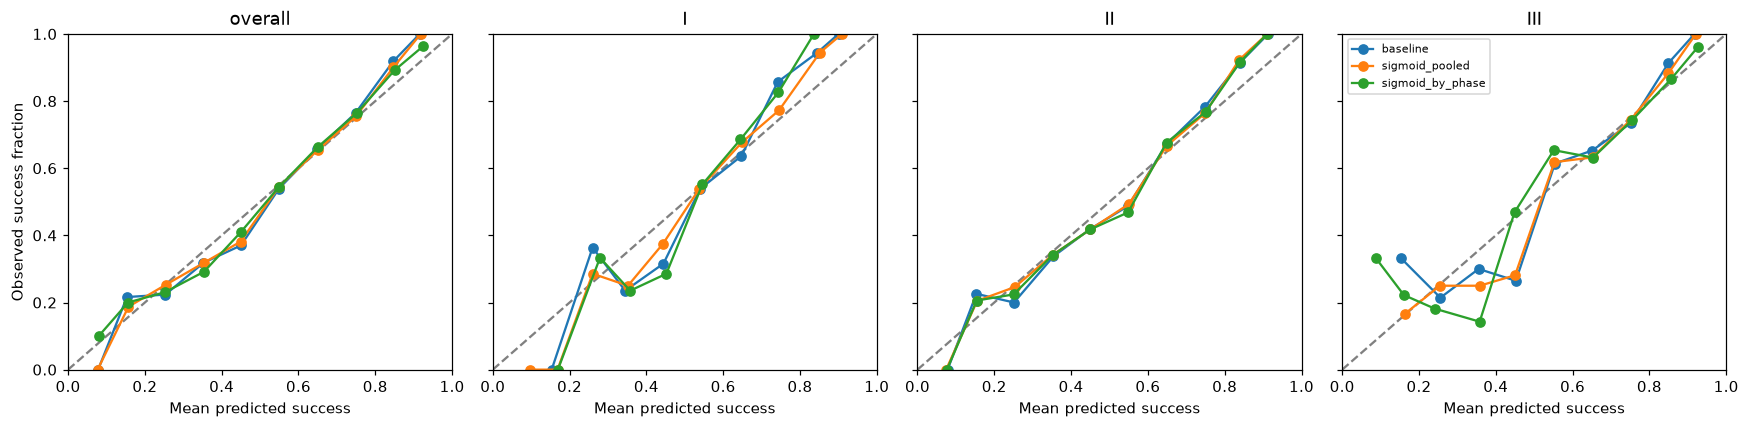

In [35]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, phase in zip(axes, ('overall', *PHASES)):
    ax.plot([0,1], [0,1], '--', color='gray')
    for candidate in ('baseline','sigmoid_pooled','sigmoid_by_phase'):
        table = bins.loc[bins.phase.eq(phase) & bins.candidate.eq(candidate) & bins.n.gt(0)]
        ax.plot(table.mean_probability, table.observed_success_rate, 'o-', label=candidate)
    ax.set(title=phase, xlabel='Mean predicted success', xlim=(0,1), ylim=(0,1))
axes[0].set_ylabel('Observed success fraction')
axes[-1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(CAL_OUTPUT / 'notebook_reliability.png', dpi=140)
plt.show()


## Findings

The historical pooled sigmoid wins overall (0.57221 versus 0.57375 baseline); phase-specific sigmoid achieves 0.57261 overall and the best Phase III loss (0.53400). Phase III baseline mean success is 66.05% versus 66.12% observed; its >=0.8 tail is underconfident, not broadly overconfident. Improvements are small and not proof of statistical significance or better later-year test performance. Validation and leaderboard performance are different quantities; no public score is claimed for these candidates.


In [36]:
after = protected_hashes()
assert all(after.get(path) == digest for path, digest in ORIGINAL_HASHES.items())
print('Existing source files, data, models, reports, predictions and submissions are unchanged.')


Existing source files, data, models, reports, predictions and submissions are unchanged.
